# TOFFEE Purity: Red Noise Smoothing

Noise in a light curve isn't always independent from one cadence to the next. **White noise** fluctuates randomly, with no memory of the point before it. **Red noise** is the opposite: correlated, slow-varying noise, where nearby points drift together rather than scattering independently, so it shows up as a wandering trend rather than a patternless scatter. A first `detect_flares()` pass can mistake a stretch of this kind of residual, low-frequency wandering (or genuine leftover instrumental drift) for a flare if it happens to creep over the detection threshold: points that pass every check `detect_flares()` runs but aren't real flares. `red_noise_smoothing()` masks the large, obviously-real flares from that first pass, re-detrends the rest with a small `wotan` window, and lets you detect again on the cleaned-up result. This notebook covers the core function, the visualizer built to help you choose its settings, and why the method is best judged over a whole catalogue rather than one light curve at a time.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import toffee

## 1. Reload the light curve and detect flares (first pass)

This notebook uses TIC 100481123, sector 6: a fast-rotating star whose short-window `flatten()` leaves real residual structure behind, exactly the case `red_noise_smoothing()` is built for.

In [2]:
################ TUTORIAL TARGET ################
#change these two values to try a different star/sector
TIC_ID = 100481123
SECTOR = 6

import lightkurve as lk

search_result = lk.search_lightcurve(f'TIC {TIC_ID}', mission = 'TESS', author = 'SPOC',
                                     exptime = 120, sector = SECTOR)
lc = search_result.download()

time = np.asarray(lc.time.value, dtype = float)
flux = np.asarray(lc.flux.value, dtype = float)
flux_err = np.asarray(lc.flux_err.value, dtype = float)
quality = np.asarray(lc.quality.value, dtype = int)

finite = np.isfinite(time) & np.isfinite(flux) & np.isfinite(flux_err)
time, flux, flux_err, quality = time[finite], flux[finite], flux_err[finite], quality[finite]

orbit_time, lc_quad, lc_wotan, periodic = toffee.flatten(time, flux, flux_err, short_window = 0.25)
flat_flux, flat_flux_err = lc_wotan[0], lc_wotan[1]

#flatten() only keeps cadences that fall inside a known TESS orbit window, so check quality
#still lines up one-to-one before reusing it -- if it doesn't, fall back to no quality
#filtering rather than misaligning by position (same check as notebook 1)
if len(orbit_time) == len(quality):
    orbit_quality = quality
else:
    print(f'{len(quality) - len(orbit_time)} cadence(s) fell outside TESS orbit coverage and '
         'were dropped by flatten() -- skipping quality filtering to avoid misalignment.')
    orbit_quality = np.zeros(len(orbit_time))

flares_first = toffee.detect_flares(orbit_time, flat_flux, flat_flux_err, orbit_quality)
print(f'{len(flares_first)} flares found before smoothing')
flares_first

6 cadence(s) fell outside TESS orbit coverage and were dropped by flatten() -- skipping quality filtering to avoid misalignment.


7 flares found before smoothing


,T_peak,T_start,T_end,Amplitude,ED,Primary_or_Secondary,Num_Points,Num_Abv_Threshold,Amp_Sigma
0,1468.697671,1468.693504,1468.706004,0.034450,24.186078,primary,10,7,8.082281
1,1470.122671,1470.119893,1470.131004,0.036423,18.337487,primary,9,5,8.545172
2,1474.526814,1474.525425,1474.532370,0.033866,12.645477,primary,6,4,7.945232
3,1479.086489,1479.082322,1479.092045,0.019668,12.869266,primary,8,6,4.614170
4,1480.064259,1480.061481,1480.100369,0.089166,88.150596,primary,29,25,20.919006
5,1486.323888,1486.316944,1486.326666,0.022329,14.681547,primary,8,6,5.238611
6,1489.098826,1489.097437,1489.104381,0.044492,14.292733,primary,6,4,10.438297


## 2. `red_noise_smoothing()`

```python
def red_noise_smoothing(time, flux, flare_frame, clip_amp=5, window_length=0.05,
                        break_tolerance=0, method='biweight', fill_gaps='raw'):
```

| Argument | Type | Default | Meaning |
|---|---|---|---|
| `time` | array | required | Time coordinates of the already-detrended light curve |
| `flux` | array | required | Flux values, same length as `time` |
| `flare_frame` | DataFrame | required | The `detect_flares()` result from a first pass; tells the function which flares to protect |
| `clip_amp` | float | `5` | Flares with `Amp_Sigma` above this are masked out before re-detrending, so `wotan` fits around them instead of flattening them away |
| `window_length` | float | `0.05` | The `wotan` window length, in days, for the re-detrend. The setting `plot_example()` (section 4) helps you choose |
| `break_tolerance` | float | `0` | `wotan`'s own break-tolerance, in days: how big a gap splits the light curve into separate segments to detrend independently |
| `method` | str | `'biweight'` | `wotan` detrending method |
| `fill_gaps` | str | `'raw'` | What to do with cadences `wotan` couldn't fit a trend for (see below) |

Returns `(flatten_lc, trend_lc)`: the re-smoothed flux, and the trend that was divided out to get it.

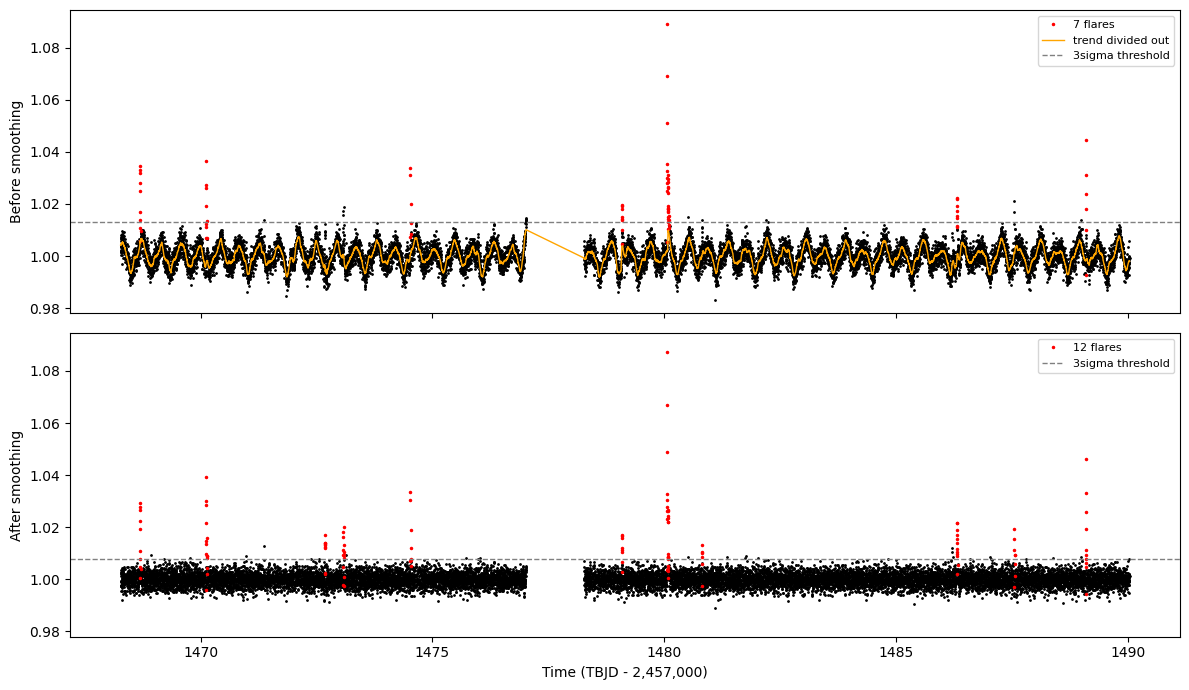

In [3]:
smoothed_flux, smoothed_trend = toffee.red_noise_smoothing(orbit_time, flat_flux, flares_first,
                                                           clip_amp = 5, window_length = 0.05)

#detect again on the smoothed flux so the 'after' panel can be colored the same way -- by
#which points actually belong to a detected flare, not just eyeballed
flares_second = toffee.detect_flares(orbit_time, smoothed_flux, flat_flux_err, orbit_quality)

#TOFFEE's own definition of sigma (84th percentile of flux - 1), recomputed for each flux
#array separately since smoothing changes the spread, not just the mean
flux_std_before = np.nanpercentile(flat_flux - 1, 84)
flux_std_after = np.nanpercentile(smoothed_flux - 1, 84)
primary_threshold = 3.0
threshold_before = 1 + primary_threshold * flux_std_before
threshold_after = 1 + primary_threshold * flux_std_after

#a point 'belongs to a flare' if it falls inside any detected flare's T_start:T_end window
def flare_point_mask(time, flares):
    mask = np.full(len(time), False)
    for _, flare in flares.iterrows():
        mask |= (time >= flare['T_start']) & (time <= flare['T_end'])
    return mask

flare_mask_before = flare_point_mask(orbit_time, flares_first)
flare_mask_after = flare_point_mask(orbit_time, flares_second)

fig, axs = plt.subplots(2, 1, figsize = (12, 7), sharex = True)
axs[0].plot(orbit_time[~flare_mask_before], flat_flux[~flare_mask_before], '.', color = 'black', markersize = 2)
axs[0].plot(orbit_time[flare_mask_before], flat_flux[flare_mask_before], '.', color = 'red', markersize = 3,
           label = f'{len(flares_first)} flares')
axs[0].plot(orbit_time, smoothed_trend, color = 'orange', linewidth = 1, label = 'trend divided out')
axs[0].axhline(threshold_before, color = 'grey', linestyle = '--', linewidth = 1,
              label = f'{primary_threshold:.0f}sigma threshold')
axs[0].set_ylabel('Before smoothing')
axs[0].legend(fontsize = 8, loc = 'upper right')
axs[1].plot(orbit_time[~flare_mask_after], smoothed_flux[~flare_mask_after], '.', color = 'black', markersize = 2)
axs[1].plot(orbit_time[flare_mask_after], smoothed_flux[flare_mask_after], '.', color = 'red', markersize = 3,
           label = f'{len(flares_second)} flares')
axs[1].axhline(threshold_after, color = 'grey', linestyle = '--', linewidth = 1,
              label = f'{primary_threshold:.0f}sigma threshold')
axs[1].legend(fontsize = 8, loc = 'upper right')
#same y-limits as the panel above, so a real shift is visible instead of hidden by each
#panel auto-scaling to its own data
axs[1].set_ylim(axs[0].get_ylim())
axs[1].set_ylabel('After smoothing')
axs[1].set_xlabel('Time (TBJD - 2,457,000)')
plt.tight_layout()
plt.show()

**`fill_gaps`:** `wotan` sometimes has no valid data inside its window to fit a trend for a cadence, near a large masked flare, for instance. `fill_gaps='raw'` (the default) leaves the original, pre-smoothing flux at those cadences; `fill_gaps='interpolate'` linearly interpolates the trend from its nearest valid neighbors instead. Either way, cadences where `wotan` truly returned nothing (both flux and trend are `NaN`) still need dropping before detecting again, covered in section 5.

## 3. `lightcurve_quality()`: how flat is this light curve, really?

```python
def lightcurve_quality(flux, flux_err):
```

| Argument | Type | Meaning |
|---|---|---|
| `flux` | array | Flux values from an already-detrended light curve |
| `flux_err` | array | Flux uncertainties, same length as `flux` |

Returns a single float: the median flux error divided by TOFFEE's own robust sigma (the 84th percentile of `flux - 1`, the same spread `detect_flares()` builds its thresholds on). **Higher means flatter**: a value near 1 means the measurement errors are about the same size as the actual scatter in the light curve, which is what a well-detrended, noise-dominated light curve looks like. A value well below 1 means there's more scatter than the error bars can explain: residual, uncorrected structure. This is the metric section 6 uses to find which light curves in a sample benefit most from smoothing.

In [4]:
print(f'quality before smoothing: {toffee.lightcurve_quality(flat_flux, flat_flux_err):.3f}')
print(f'quality after smoothing:  {toffee.lightcurve_quality(smoothed_flux, flat_flux_err):.3f}')

quality before smoothing: 0.617
quality after smoothing:  1.037


## 4. `plot_example()`: choosing `window_length` by eye

```python
def plot_example(time, flux, flux_err, quality, ..., windows=(0.03, 0.05, 0.10),
                 savepath=None, target=None, sector=None):
```

This is the visualizer built specifically for `red_noise_smoothing()`. Pass it the *raw* light curve (it calls `flatten()` and `detect_flares()` itself, so you don't need to run those first) and a list of candidate window lengths. It plots one panel per window with the trend it divided out drawn on top, and titles each panel with the resulting `lightcurve_quality()` and flare count, so you can compare several choices side by side before committing to one. Every other argument matches `flatten_detect_smooth()` (section 5) and passes straight through to `flatten()`/`detect_flares()`.

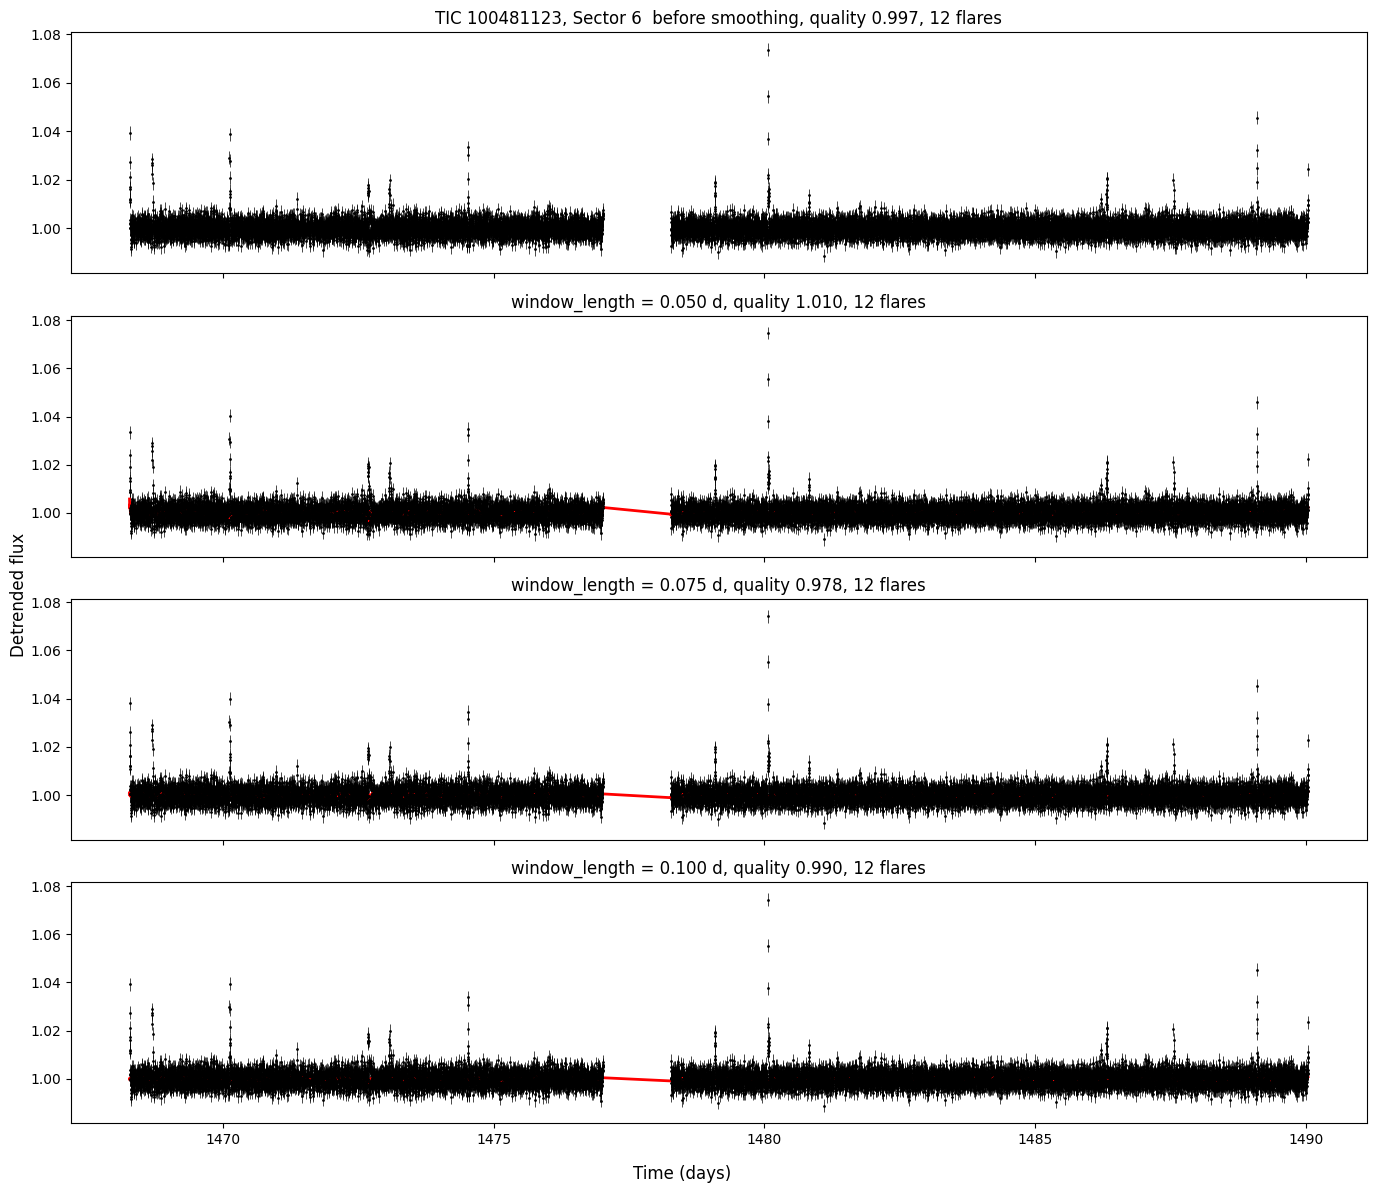

In [5]:
fig = toffee.plot_example(time, flux, flux_err, quality,
                          windows = (0.05, 0.075, 0.1), target = TIC_ID, sector = SECTOR)

The top panel is the light curve as it comes out of `flatten()`, before any smoothing. Notice it's already fairly flat (quality 0.997), much better than the 0.617 quality measured in section 3. That's because `plot_example()` runs `flatten()` with `periodogram=[0.1, 10]` by default, while section 1's manual call left it off. The periodogram step removes most of this target's fast rotational modulation on its own, so `red_noise_smoothing()` was doing its work in sections 1-3 on the harder case, with that correction switched off. All three windows tried here keep the same 12 flares and land at a similarly flat quality (1.010, 0.978, 0.990), confirming the choice barely matters once a window is anywhere in a reasonable range, which is the reassuring answer `plot_example()` is meant to give before you commit to one.

## 5. `flatten_detect_smooth()`: the whole pipeline in one call

Running `flatten()`, a first `detect_flares()`, `red_noise_smoothing()`, and a second `detect_flares()` by hand every time is a lot of repetition. `flatten_detect_smooth()` does all four steps and returns everything needed to compare the two passes.

| Argument group | Covers |
|---|---|
| Lightcurve prep | `flag_values`, `min_break`, `clip_breaks` |
| Detrending | `short_window`, `periodogram` |
| Detection | `primary_threshold`, `secondary_threshold`, `num_consec`, `num_consec_sec`, `loss` |
| Flare modeling | `rise_bounds`, `rise_func`, `decay_func`, `fit_peak`, `p0_decay`, `decay_bounds`, `fit_multiple_secs` |
| Flare start/end | `prim_marginal_threshold`, `num_below_threshold` |
| Red noise smoothing | `window`, `clip_amp`, `break_tolerance`, `method`, `fill_gaps` |

Every one of those is a `detect_flares()`/`flatten()`/`red_noise_smoothing()` argument already covered in notebooks 1-3 and above; `flatten_detect_smooth()` just runs the whole sequence with them. It takes the **raw** light curve (same as `plot_example()`), not an already-detrended one.

Returns a dictionary:

| Key | Contents |
|---|---|
| `time`, `flux`, `flux_err` | The detrended (but not yet smoothed) light curve |
| `smoothed`, `trend` | `red_noise_smoothing()`'s output |
| `keep` | Boolean mask marking the finite (non-`NaN`) cadences of `smoothed` |
| `first`, `second` | The two `detect_flares()` DataFrames, before and after smoothing |
| `recovered`, `dropped` | Boolean arrays indexing `first`: which flares survived into `second`, and which didn't |
| `new`, `pre_existing` | Boolean arrays indexing `second`: which flares are new after smoothing, and which were already in `first`|

In [6]:
result = toffee.flatten_detect_smooth(time, flux, flux_err, quality)

print(f"first pass:  {len(result['first'])} flares")
print(f"second pass: {len(result['second'])} flares")
print(f"dropped: {result['dropped'].sum()}, new: {result['new'].sum()}, "
     f"recovered: {result['recovered'].sum()}, pre_existing: {result['pre_existing'].sum()}")

first pass:  14 flares
second pass: 13 flares
dropped: 1, new: 0, recovered: 13, pre_existing: 13


## 6. `match_flares()` / `pair_flares()`: how the before/after comparison actually works

`flatten_detect_smooth()` uses these internally to build `recovered`/`dropped`/`new`, worth knowing about directly since they're useful any time two `detect_flares()` runs on related light curves need comparing.

```python
def match_flares(before, after, cadence=120):
def pair_flares(before, after, cadence=120):
```

| Argument | Type | Meaning |
|---|---|---|
| `before`, `after` | DataFrame | Two `detect_flares()` results to compare |
| `cadence` | float | The light curve's cadence, in **seconds**: the slack allowed when checking whether two flare windows touch |

Both match by **overlap of the `T_start`-`T_end` windows**, not by comparing peak times. Re-detecting on a re-baselined light curve routinely shifts a fitted peak by a cadence or two, and a peak-time match would count those flares as lost when they're really still there. `match_flares` returns `(fraction, kept)`: the fraction of `before` found in `after`, and a boolean array marking which. `pair_flares` returns one integer per `before` row: the index of its best-overlapping match in `after`, or `-1` if nothing overlaps, so you can compare a matched pair's fitted properties directly rather than just checking whether a match exists.

In [7]:
fraction_kept, kept = toffee.match_flares(result['first'], result['second'])
print(f'{fraction_kept:.0%} of the first-pass flares survived smoothing')
print(result['first'][~kept][['T_peak', 'Amplitude', 'Amp_Sigma']])

93% of the first-pass flares survived smoothing
        T_peak  Amplitude  Amp_Sigma
6  1476.744844   0.013566   4.918972


## 7. This works best over a catalogue

Section 6's numbers are for one light curve: interesting, but anecdotal. `red_noise_smoothing()`'s real value shows up across a whole sample, especially the light curves with low `lightcurve_quality()` (poor detrending), where residual structure is most likely to be masquerading as flares, or hiding real ones. Looping `flatten_detect_smooth()` over many targets and comparing the effect against each one's quality is the way to see that pattern, rather than judging the method from a single star.

`flatten()` and `flatten_detect_smooth()` raise a real exception, a `toffee.ToffeeError` (or one of its subclasses, `LightCurveError`/`DetrendingError`), instead of returning a sentinel value, specifically so a loop over many light curves can skip the ones TOFFEE can't handle without masking a genuine bug:

```python
try:
    result = toffee.flatten_detect_smooth(time, flux, flux_err, quality)
except toffee.ToffeeError as error:
    print(target, 'skipped:', error)
    continue
```

In [8]:
#a small catalogue -- the same targets already used across notebooks 1-3, plus a few
#new ones, run through the whole pipeline exactly as a real catalogue-building loop would
catalogue_targets = [
    (84336253, 43), (114029415, 42), (70744265, 2), (293968698, 34),
    (308542808, 8), (167344029, 36), (286122000, 58), (382043650, 13),
]

catalogue_rows = []
for tic, sector in catalogue_targets:
    search_result = lk.search_lightcurve(f'TIC {tic}', mission = 'TESS', author = 'SPOC',
                                         exptime = 120, sector = sector)
    cat_lc = search_result.download()
    cat_time = np.asarray(cat_lc.time.value, dtype = float)
    cat_flux = np.asarray(cat_lc.flux.value, dtype = float)
    cat_flux_err = np.asarray(cat_lc.flux_err.value, dtype = float)
    cat_quality = np.asarray(cat_lc.quality.value, dtype = int)

    try:
        cat_result = toffee.flatten_detect_smooth(cat_time, cat_flux, cat_flux_err, cat_quality)
    except toffee.ToffeeError as error:
        print(f'TIC {tic} skipped: {error}')
        continue

    lc_quality = toffee.lightcurve_quality(cat_result['flux'], cat_result['flux_err'])
    catalogue_rows.append({
        'TIC': tic, 'quality': lc_quality,
        'first': len(cat_result['first']), 'second': len(cat_result['second']),
        'dropped': int(cat_result['dropped'].sum()), 'new': int(cat_result['new'].sum()),
    })

catalogue = pd.DataFrame(catalogue_rows).sort_values('quality').reset_index(drop = True)
catalogue

,TIC,quality,first,second,dropped,new
0,167344029,0.890052,12,13,0,1
1,286122000,0.917169,7,7,0,0
2,293968698,0.959094,9,9,0,0
3,308542808,0.973437,10,10,0,0
4,114029415,0.984846,9,6,4,0
5,70744265,1.000649,4,2,0,0
6,382043650,1.023729,10,10,0,0
7,84336253,1.031440,5,4,1,0


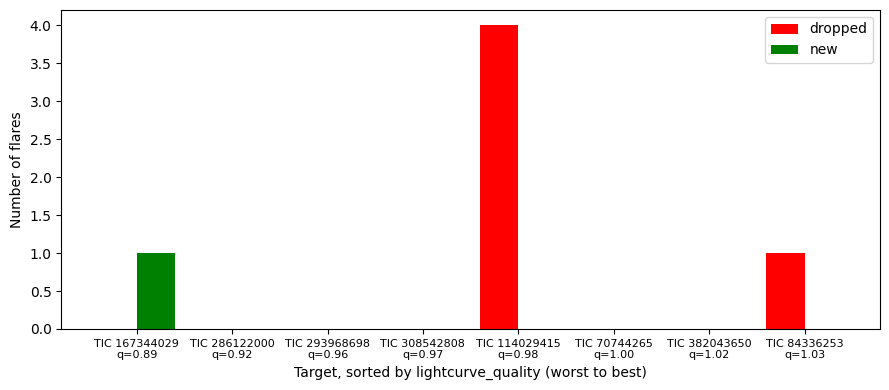

In [9]:
fig, ax = plt.subplots(figsize = (9, 4))
x = np.arange(len(catalogue))
ax.bar(x - 0.2, catalogue['dropped'], width = 0.4, color = 'red', label = 'dropped')
ax.bar(x + 0.2, catalogue['new'], width = 0.4, color = 'green', label = 'new')
ax.set_xticks(x)
ax.set_xticklabels([f'TIC {t}\nq={q:.2f}' for t, q in zip(catalogue['TIC'], catalogue['quality'])],
                   fontsize = 8)
ax.set_ylabel('Number of flares')
ax.set_xlabel('Target, sorted by lightcurve_quality (worst to best)')
ax.legend()
plt.tight_layout()
plt.show()

Only 8 stars, so this is a demonstration of the *workflow*, not a statistically robust trend, and the honest reading of these particular 8 is that the effect doesn't line up neatly with quality alone. Three targets actually changed:

- **TIC 167344029** (quality 0.89, the **worst** of the set) is the only target where smoothing found a **new** flare: a real flare recovered from under residual noise.
- **TIC 114029415** (quality 0.98, solidly mid-pack) had **4 flares dropped**, the single largest change in the whole sample, on a light curve that wasn't obviously the worst-detrended one going in.
- **TIC 84336253** (quality ~1.03, already fairly flat) had 1 flare dropped: the edge artifact from notebook 2.

The other five, already close to `quality=1`, show no change at all. So the real pattern in a small sample like this is noisier than "low quality always means a big effect": quality is a reasonable first filter for *which* light curves to inspect, but not a guarantee of how much smoothing will change, or in which direction. That's exactly why this needs catalogue scale (hundreds of targets, not eight) to see a systematic trend rather than reason from individual cases, and worth checking `dropped`/`new` directly rather than assuming quality alone tells the story.

## 8. What actually got dropped, and what actually got found

"Fewer/more flares" is an abstract way to judge a purity method; better to look at the actual flares involved. TIC 114029415 had the biggest change (4 dropped); TIC 167344029 had the only new find. Both from the catalogue above, reprocessed individually here to keep their intermediate arrays around for plotting.

In [10]:
dropped_search = lk.search_lightcurve('TIC 114029415', mission = 'TESS', author = 'SPOC',
                                      exptime = 120, sector = 42)
dropped_lc = dropped_search.download()
dropped_time = np.asarray(dropped_lc.time.value, dtype = float)
dropped_flux = np.asarray(dropped_lc.flux.value, dtype = float)
dropped_flux_err = np.asarray(dropped_lc.flux_err.value, dtype = float)
dropped_quality = np.asarray(dropped_lc.quality.value, dtype = int)

dropped_result = toffee.flatten_detect_smooth(dropped_time, dropped_flux, dropped_flux_err,
                                              dropped_quality)
dropped_flares = dropped_result['first'][dropped_result['dropped']]
dropped_flares[['T_peak', 'T_start', 'T_end', 'Amplitude', 'Num_Points', 'Amp_Sigma']]

,T_peak,T_start,T_end,Amplitude,Num_Points,Amp_Sigma
1,2448.181383,2448.166104,2448.204997,0.352096,29,6.276990
2,2448.218887,2448.209164,2448.225832,0.253710,13,4.523024
3,2448.234167,2448.229999,2448.249446,0.287495,15,5.125312
4,2448.261947,2448.260558,2448.270281,0.217473,8,3.876999


All four cluster within the same 0.1-day span. Zoom in on that span, before and after smoothing, with the four flagged peaks marked, **on a shared y-axis**, and with the actual `smoothed - detrended` difference plotted directly, since two independently-scaled panels can make a real correction look like no change at all.

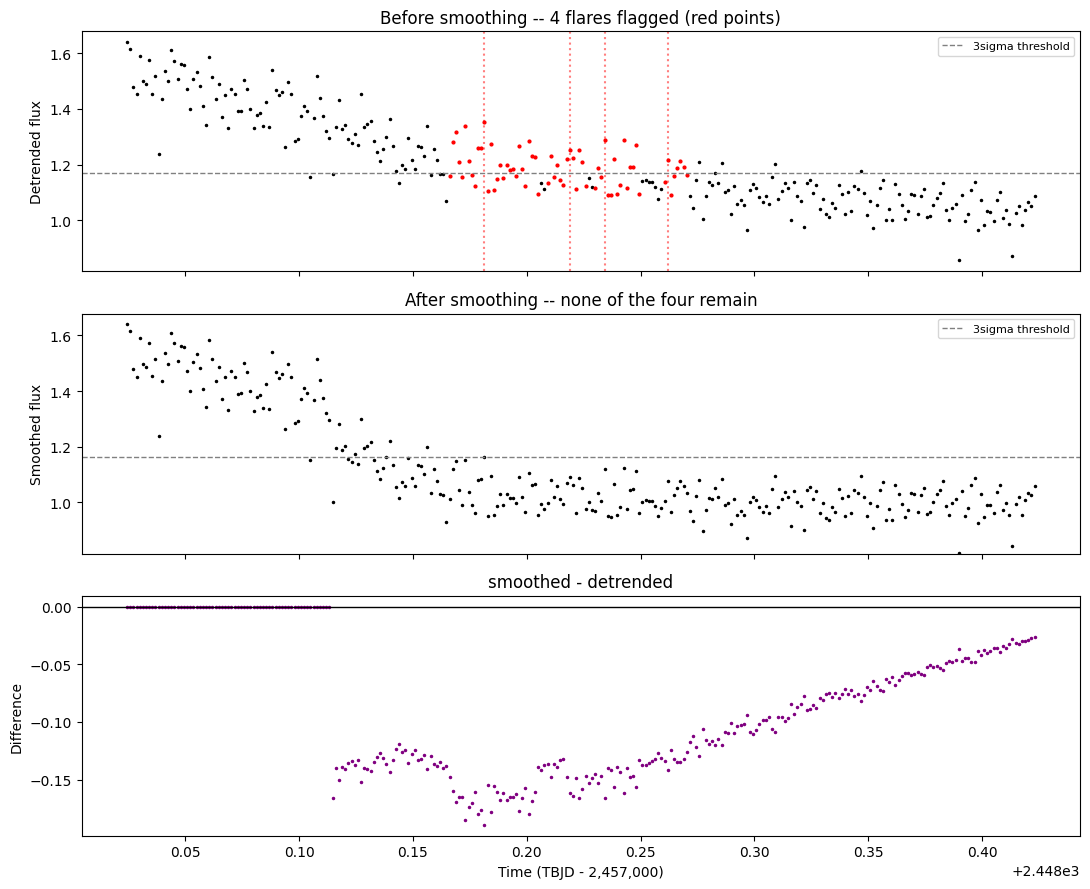

median |correction| in this window: 0.0945
max |correction| in this window:    0.1892


In [11]:
zoom_time, zoom_flux = dropped_result['time'], dropped_result['flux']
zoom_smoothed, zoom_keep = dropped_result['smoothed'], dropped_result['keep']
zoom_center = dropped_flares['T_peak'].mean()
zoom_mask = np.abs(zoom_time - zoom_center) < 0.2
zoom_mask_smooth = zoom_mask & zoom_keep

#TOFFEE's own 3-sigma detection threshold, recomputed from each flux array's own spread --
#drawing it directly answers 'are there really 3+ consecutive points above the line'
zoom_std_before = np.nanpercentile(zoom_flux - 1, 84)
zoom_std_after = np.nanpercentile(zoom_smoothed[zoom_keep] - 1, 84)
zoom_threshold_before = 1 + 3.0 * zoom_std_before
zoom_threshold_after = 1 + 3.0 * zoom_std_after

#a point 'belongs to a flare' if it falls inside a detected flare's window -- 'before' uses
#the 4 flagged first-pass flares; 'after' uses whatever the SECOND pass actually found here,
#so the coloring reflects real detections rather than just replaying the first-pass windows
def flare_point_mask(time, flares):
    mask = np.full(len(time), False)
    for _, flare in flares.iterrows():
        mask |= (time >= flare['T_start']) & (time <= flare['T_end'])
    return mask

flare_pts_before = flare_point_mask(zoom_time[zoom_mask], dropped_flares)
#restrict to the four ORIGINAL windows, not every second-pass flare in the zoomed range --
#a separate, genuinely real flare sits just before this window (see below) and coloring
#every current detection would paint it red too, muddying the 'none of the four' point
in_one_of_the_four = flare_point_mask(zoom_time[zoom_mask_smooth], dropped_flares)
flare_pts_after = in_one_of_the_four & flare_point_mask(zoom_time[zoom_mask_smooth], dropped_result['second'])

fig, axs = plt.subplots(3, 1, figsize = (11, 9), sharex = True)
axs[0].plot(zoom_time[zoom_mask][~flare_pts_before], zoom_flux[zoom_mask][~flare_pts_before],
           '.', color = 'black', markersize = 3)
axs[0].plot(zoom_time[zoom_mask][flare_pts_before], zoom_flux[zoom_mask][flare_pts_before],
           '.', color = 'red', markersize = 4)
axs[0].axhline(zoom_threshold_before, color = 'grey', linestyle = '--', linewidth = 1, label = '3sigma threshold')
for t_peak in dropped_flares['T_peak']:
    axs[0].axvline(t_peak, color = 'red', linestyle = ':', alpha = 0.5)
axs[0].set_title('Before smoothing -- 4 flares flagged (red points)')
axs[0].set_ylabel('Detrended flux')
axs[0].legend(fontsize = 8, loc = 'upper right')

axs[1].plot(zoom_time[zoom_mask_smooth][~flare_pts_after], zoom_smoothed[zoom_mask_smooth][~flare_pts_after],
           '.', color = 'black', markersize = 3)
axs[1].plot(zoom_time[zoom_mask_smooth][flare_pts_after], zoom_smoothed[zoom_mask_smooth][flare_pts_after],
           '.', color = 'red', markersize = 4)
axs[1].axhline(zoom_threshold_after, color = 'grey', linestyle = '--', linewidth = 1, label = '3sigma threshold')
axs[1].set_title('After smoothing -- none of the four remain')
axs[1].set_ylabel('Smoothed flux')
axs[1].legend(fontsize = 8, loc = 'upper right')
#same y-limits as the panel above, so a real shift is actually visible instead of being
#hidden by each panel auto-scaling to its own data
axs[1].set_ylim(axs[0].get_ylim())

axs[2].plot(zoom_time[zoom_mask_smooth], zoom_smoothed[zoom_mask_smooth] - zoom_flux[zoom_mask_smooth],
           '.', color = 'purple', markersize = 3)
axs[2].axhline(0, color = 'black', linewidth = 1)
axs[2].set_title('smoothed - detrended')
axs[2].set_ylabel('Difference')
axs[2].set_xlabel('Time (TBJD - 2,457,000)')
plt.tight_layout()
plt.show()

print(f'median |correction| in this window: {np.nanmedian(np.abs(zoom_smoothed[zoom_mask_smooth] - zoom_flux[zoom_mask_smooth])):.4f}')
print(f'max |correction| in this window:    {np.nanmax(np.abs(zoom_smoothed[zoom_mask_smooth] - zoom_flux[zoom_mask_smooth])):.4f}')

That's not four flares. It's one smooth, slowly-declining trend (flux drifting from ~1.5 down to ~1.0 over a few hours) that a first detection pass sliced into four separate threshold crossings, purely because the trend itself was carrying the flux above the 3σ line in four different places. The correction really is there (median ~0.11 in this window, comparable to the flares' own amplitudes of 0.2-0.35); it's just easy to miss on two separately-scaled panels, since the *shape* of the decline barely changes, only its baseline level. `red_noise_smoothing` recognizes that shape as the low-frequency residual it's designed to remove, not four flares, and the second pass correctly finds none of them: these are exactly the "crap flares" the method exists to catch.

(The flat, exactly-zero stretch at the start of the difference panel is unrelated to these four. It's the tail end of a separate, genuinely huge flare (`Amp_Sigma=38.7`) just before this window, whose masked-out protection zone extends to t≈2448.162. `wotan` has no local data to fit a trend there, so `fill_gaps='raw'` leaves that stretch untouched. All four dropped flares sit past that point, in the region that does get corrected.)

In [12]:
new_search = lk.search_lightcurve('TIC 167344029', mission = 'TESS', author = 'SPOC',
                                   exptime = 120, sector = 36)
new_lc = new_search.download()
new_time = np.asarray(new_lc.time.value, dtype = float)
new_flux = np.asarray(new_lc.flux.value, dtype = float)
new_flux_err = np.asarray(new_lc.flux_err.value, dtype = float)
new_quality = np.asarray(new_lc.quality.value, dtype = int)

new_result = toffee.flatten_detect_smooth(new_time, new_flux, new_flux_err, new_quality)
new_flare = new_result['second'][new_result['new']]
new_flare[['T_peak', 'T_start', 'T_end', 'Amplitude', 'Num_Points', 'Amp_Sigma']]

,T_peak,T_start,T_end,Amplitude,Num_Points,Amp_Sigma
11,2305.392893,2305.388727,2305.398449,0.007089,8,4.756442


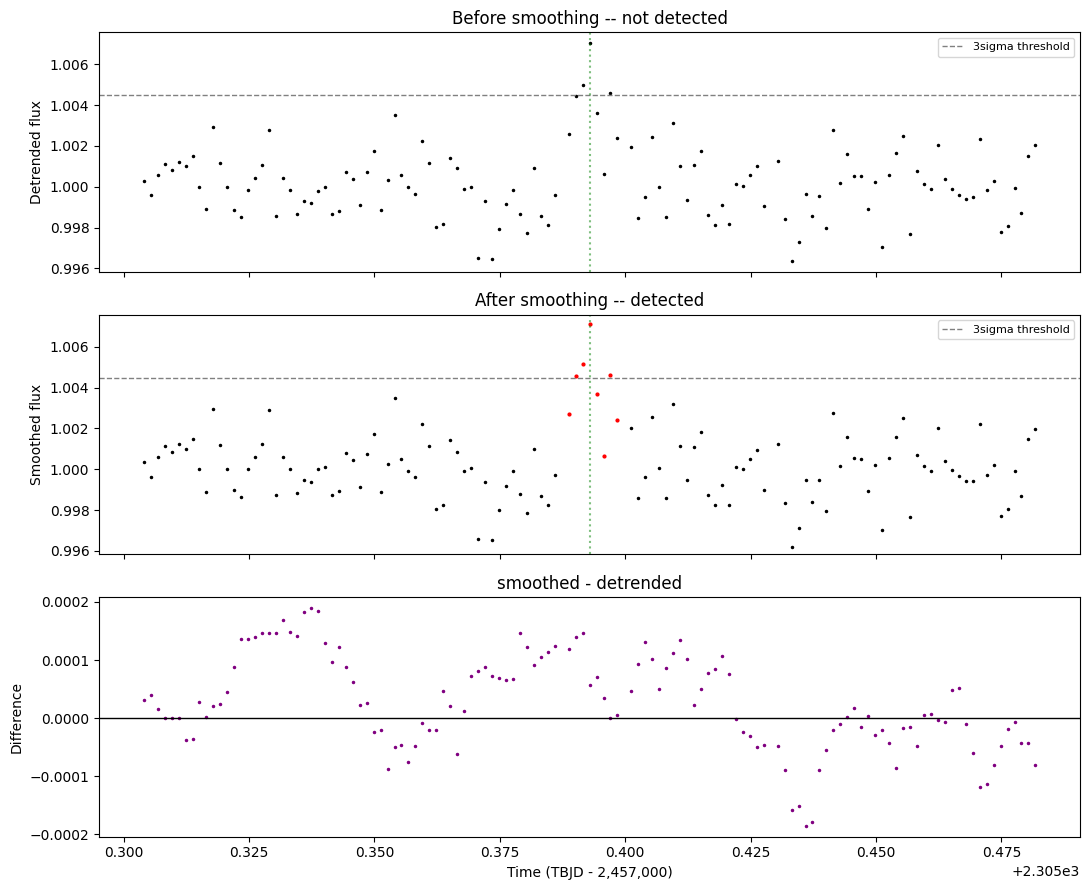

median |correction| here: 0.000054


In [13]:
new_time_arr, new_flux_arr = new_result['time'], new_result['flux']
new_smoothed, new_keep = new_result['smoothed'], new_result['keep']
new_peak_time = new_flare['T_peak'].iloc[0]
new_zoom = np.abs(new_time_arr - new_peak_time) < 0.09
new_zoom_smooth = new_zoom & new_keep

#same 3-sigma threshold treatment as the 'dropped' example above
new_std_before = np.nanpercentile(new_flux_arr - 1, 84)
new_std_after = np.nanpercentile(new_smoothed[new_keep] - 1, 84)
new_threshold_before = 1 + 3.0 * new_std_before
new_threshold_after = 1 + 3.0 * new_std_after

#color by what each pass ACTUALLY detected, not by where the flare ends up -- 'before' should
#show no red at all (that's what 'not detected' means), 'after' should show red exactly where
#the second pass's own flare table says a flare is
def flare_point_mask(time, flares):
    mask = np.full(len(time), False)
    for _, flare in flares.iterrows():
        mask |= (time >= flare['T_start']) & (time <= flare['T_end'])
    return mask

new_flare_pts_before = flare_point_mask(new_time_arr[new_zoom], new_result['first'])
new_flare_pts_after = flare_point_mask(new_time_arr[new_zoom_smooth], new_result['second'])

fig, axs = plt.subplots(3, 1, figsize = (11, 9), sharex = True)
axs[0].plot(new_time_arr[new_zoom][~new_flare_pts_before], new_flux_arr[new_zoom][~new_flare_pts_before],
           '.', color = 'black', markersize = 3)
axs[0].plot(new_time_arr[new_zoom][new_flare_pts_before], new_flux_arr[new_zoom][new_flare_pts_before],
           '.', color = 'red', markersize = 4)
axs[0].axhline(new_threshold_before, color = 'grey', linestyle = '--', linewidth = 1, label = '3sigma threshold')
axs[0].axvline(new_peak_time, color = 'green', linestyle = ':', alpha = 0.5)
axs[0].set_title('Before smoothing -- not detected')
axs[0].set_ylabel('Detrended flux')
axs[0].legend(fontsize = 8, loc = 'upper right')

axs[1].plot(new_time_arr[new_zoom_smooth][~new_flare_pts_after], new_smoothed[new_zoom_smooth][~new_flare_pts_after],
           '.', color = 'black', markersize = 3)
axs[1].plot(new_time_arr[new_zoom_smooth][new_flare_pts_after], new_smoothed[new_zoom_smooth][new_flare_pts_after],
           '.', color = 'red', markersize = 4)
axs[1].axhline(new_threshold_after, color = 'grey', linestyle = '--', linewidth = 1, label = '3sigma threshold')
axs[1].axvline(new_peak_time, color = 'green', linestyle = ':', alpha = 0.5)
axs[1].set_title('After smoothing -- detected')
axs[1].set_ylabel('Smoothed flux')
axs[1].legend(fontsize = 8, loc = 'upper right')
axs[1].set_ylim(axs[0].get_ylim())

axs[2].plot(new_time_arr[new_zoom_smooth], new_smoothed[new_zoom_smooth] - new_flux_arr[new_zoom_smooth],
           '.', color = 'purple', markersize = 3)
axs[2].axhline(0, color = 'black', linewidth = 1)
axs[2].set_title('smoothed - detrended')
axs[2].set_ylabel('Difference')
axs[2].set_xlabel('Time (TBJD - 2,457,000)')
plt.tight_layout()
plt.show()

print(f'median |correction| here: {np.nanmedian(np.abs(new_smoothed[new_zoom_smooth] - new_flux_arr[new_zoom_smooth])):.6f}')

The correction here really is tiny (median ~0.00007, versus ~0.11 for the dropped cluster above), small enough that even the shared-axis, difference-panel treatment barely shows it. So the more useful question isn't "does the flux look different" but "does it cross the detection threshold differently", and `detect_flares()` requires **3 consecutive** cadences above 3σ (`num_consec=3`), not just one bright point. Check the actual sigma values at the cadences spanning the bump:

In [14]:
flux_std_before = np.nanpercentile(new_flux_arr - 1, 84)
flux_std_after = np.nanpercentile(new_smoothed[new_keep] - 1, 84)

bump_mask = np.abs(new_time_arr - new_peak_time) < 0.01
sigma_before = (new_flux_arr[bump_mask] - 1) / flux_std_before
sigma_after = (new_smoothed[bump_mask] - 1) / flux_std_after

comparison = pd.DataFrame({'time': new_time_arr[bump_mask],
                           'sigma_before': sigma_before, 'sigma_after': sigma_after})
comparison

,time,sigma_before,sigma_after
0,2305.383171,-0.952134,-0.885661
1,2305.384560,-1.262734,-1.191602
2,2305.385949,-0.275005,-0.193329
3,2305.388727,1.731332,1.818945
4,2305.390116,2.963088,3.068800
5,2305.391505,3.334427,3.447354
6,2305.392893,4.698132,4.756442
7,2305.394282,2.429061,2.486573
8,2305.395671,0.418540,0.443580
9,2305.397060,3.067322,3.080913


One cadence sits at 2.96σ before smoothing, just under the 3σ line, and 3.07σ after, just over it. That one cadence is what stitches together a run of **three** consecutive points above 3σ instead of two; `num_consec=3` isn't met before, and is met after. Nothing about the flare's shape changed: a slightly-improved global noise estimate (`flux_std` dropped about 0.5%, from smoothing's effect on the *rest* of the light curve, not this bump specifically) was just enough to move one borderline cadence across the line.

## Summary

- `red_noise_smoothing(time, flux, flare_frame, ...)` masks the large flares from a first `detect_flares()` pass, re-detrends the rest with a small `wotan` window, and returns `(flatten_lc, trend_lc)`.
- `lightcurve_quality(flux, flux_err)` is the metric behind 'low detrending quality': near 1 means flat and noise-dominated, well below 1 means real residual structure remains.
- `plot_example(...)` is the dedicated visualizer for choosing `window_length`: one panel per candidate window, each titled with its resulting quality and flare count.
- `flatten_detect_smooth(...)` runs the whole detrend/detect/smooth/detect-again sequence and returns both flare samples plus `match_flares`-based comparison arrays.
- `match_flares`/`pair_flares` compare two `detect_flares()` runs by **window overlap**, not peak time, since re-detection can shift a fitted peak by a cadence or two.
- The method's effect is clearest across a catalogue: light curves with poor `lightcurve_quality` are where it actually drops or recovers flares; already-flat light curves show no change, which is itself useful information.
- Inspecting the actual dropped/new flares (not just counts) matters: TIC 114029415's 4 dropped 'flares' were one slow trend sliced into pieces, and TIC 167344029's new flare was a real, unchanged bump that only cleared a slightly-improved noise floor.

Notebook 5 covers the second purity method: cutting flares on square index.